# Newton–Raphson Method — Numerical Root Finding Calculator

**Course:** Differential Equations and Numerical Analysis  

---

## 1. Project Introduction

Some equations, such as $\cos(x)=x$ or $x^3-x-2=0$, cannot be solved with a simple formula. **Numerical methods** give an *approximate* root by starting from a guess and improving it step by step.

This notebook is a small calculator for the **Newton–Raphson method**. You type a function $f(x)$, an initial guess $x_0$, a tolerance and a maximum number of iterations. The program then:

1. finds $f'(x)$ automatically with SymPy,
2. repeats the Newton–Raphson formula to get $x_1, x_2, x_3,\dots$ until the required accuracy is reached,
3. shows an iteration table, the final results, and a graph.

**How to use it:** run the cells from top to bottom (*Runtime → Run all*). To try another problem, change the values in **Section 5** (or use the one-cell playground in **Section 10**).

## 2. Mathematical Background

A **root** of $f$ is a number $r$ with $f(r)=0$.

**Idea of the method.** If $x_i$ is our current guess, the curve near $x_i$ looks like its **tangent line**

$$y = f(x_i) + f'(x_i)\,(x - x_i).$$

The tangent line crosses the $x$-axis where $y=0$. We take that crossing point as the next, better guess $x_{i+1}$. Repeating this gives $x_0 \to x_1 \to x_2 \to x_3 \to \cdots \to r$, exactly like the figure in the lecture.

## 3. Newton–Raphson Formula

$$\boxed{\,x_{i+1}=x_i-\frac{f(x_i)}{f'(x_i)},\qquad i=0,1,2,\dots\,}$$

**Condition of convergence (from the lecture):**

$$\left|\frac{f(x)\,f''(x)}{\left[f'(x)\right]^2}\right|<1$$

near the root. The program prints the value of this expression at $x_0$ and at the final point.

> ⚠️ **The method does not converge for every function or every initial guess.** It can fail when $f'(x_i)=0$ (horizontal tangent), when $x_0$ is far from the root, when $f$ is undefined at some $x_i$ (for example $\ln x$ with $x\le 0$), or when the iterates jump away or oscillate (for example $\arctan x$ with $x_0=2$).

## 4. Algorithm Explanation

For $i=0,1,2,\dots$ (up to the maximum number of iterations):

1. Calculate $f(x_i)$.
2. Calculate $f'(x_i)$ (SymPy gives the derivative formula).
3. If $f'(x_i)$ is zero or almost zero → **stop with an error** (division by zero).
4. Calculate $x_{i+1}=x_i-\dfrac{f(x_i)}{f'(x_i)}$.
5. Calculate the **absolute error** $|x_{i+1}-x_i|$.
6. If the absolute error is smaller than the tolerance → **converged**. Otherwise continue with $x_{i+1}$.

If the maximum number of iterations is reached first, the program says clearly that it **did not converge**.

**Stopping criterion.** We stop when $|x_{i+1}-x_i|<\text{tolerance}$ (absolute error). This is reasonable because Newton–Raphson converges very fast near a simple root, so the size of the last step is about the size of the previous error. The **relative error** $\dfrac{|x_{i+1}-x_i|}{|x_{i+1}|}$ is also printed, but only for information. The program never says "converged" unless this stopping condition is really satisfied.

## 5. User Inputs

Fill in the four values below.

- Use `x` as the variable. Powers: `x**2` or `x^2`. Functions: `sin, cos, tan, exp, log` (natural log), `sqrt, atan, abs`. Constants: `pi`, `e`.
- Write only the left side of $f(x)=0$ (for example `cos(x) - x`, not `cos(x) = x`).
- The tolerance can be written like `1e-10`, and $x_0$ can be written like `0.5` or `pi/4`.

In [27]:
#@title Enter your problem { display-mode: "form" }

function_text = "x**2 - 4"   #@param {type:"string"}
x0_text       = "3"          #@param {type:"string"}
tol_text      = "1e-10"      #@param {type:"string"}
max_iter_text = "50"         #@param {type:"string"}

print("f(x)               =", function_text)
print("initial guess x0   =", x0_text)
print("tolerance          =", tol_text)
print("maximum iterations =", max_iter_text)

f(x)               = x**2 - 4
initial guess x0   = 3
tolerance          = 1e-10
maximum iterations = 50


## 6. Implementation

The code is divided into three small parts: (1) imports, (2) the functions that check the input and run the method, (3) the functions that show the table, the results and the graph.

In [28]:
# ---- 6.1 Libraries ----
import math
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from sympy.parsing.sympy_parser import (parse_expr, standard_transformations,
                                        convert_xor, implicit_multiplication)
from IPython.display import display, Markdown

x = sp.Symbol("x", real=True)      # the only variable allowed in f(x)
print("Libraries loaded.")

Libraries loaded.


In [29]:
# ---- 6.2 Checking the user input ----
def read_function(text):
    """Turn the typed text into a SymPy expression in x (raises ValueError if it is invalid)."""
    names = {"x": x, "e": sp.E, "ln": sp.log, "pi": sp.pi}
    try:
        expr = parse_expr(text, local_dict=names,
                          transformations=standard_transformations + (convert_xor, implicit_multiplication))
    except Exception:
        raise ValueError(f"'{text}' is not a valid expression. Example: x**3 - x - 2")
    if not isinstance(expr, sp.Expr) or expr.free_symbols != {x}:
        raise ValueError(f"'{text}' must be an expression that uses the variable x (and no other letters).")
    return expr


def read_number(text, name):
    """Turn text such as 0.5, 1e-8 or pi/4 into a finite number."""
    try:
        value = float(sp.sympify(str(text)))
    except Exception:
        raise ValueError(f"{name} must be a number, but you typed '{text}'.")
    if not math.isfinite(value):
        raise ValueError(f"{name} must be a finite number, but you typed '{text}'.")
    return value


def safe_value(func, value):
    """Calculate func(value). Raises ValueError if the result is undefined, infinite or not real."""
    try:
        with np.errstate(all="ignore"):
            result = complex(func(np.float64(value)))
    except (ArithmeticError, ValueError, TypeError, NameError):
        raise ValueError(f"the function cannot be evaluated at x = {value:.6g}")
    if result.imag != 0 or not math.isfinite(result.real):
        raise ValueError(f"the function is undefined or infinite at x = {value:.6g}")
    return result.real

print("Input-checking functions defined.")

Input-checking functions defined.


In [30]:
# ---- 6.3 The Newton-Raphson method ----
def solve(function_text, x0_text, tol_text, max_iter_text):
    """Run Newton-Raphson. Returns a dictionary with everything (or None if the input is invalid)."""

    # Step 1: check the input
    try:
        expr = read_function(function_text)
        x0 = read_number(x0_text, "The initial guess x0")
        tol = read_number(tol_text, "The tolerance")
        max_iter = read_number(max_iter_text, "The maximum number of iterations")
        if tol <= 0:
            raise ValueError("The tolerance must be a positive number.")
        if max_iter < 1 or max_iter != int(max_iter):
            raise ValueError("The maximum number of iterations must be a positive whole number.")
    except ValueError as err:
        print("❌ Invalid input:", err)
        return None
    max_iter = int(max_iter)

    # Step 2: derivatives with SymPy, then ordinary Python functions
    d1 = sp.diff(expr, x)                      # f'(x)
    d2 = sp.diff(d1, x)                        # f''(x)  (only for the lecture's convergence condition)
    f, df, ddf = (sp.lambdify(x, e, "numpy") for e in (expr, d1, d2))

    # Step 3: the iterations
    rows = []                                  # each row: [i, x_i, f(x_i), f'(x_i), x_(i+1), absolute error]
    status = "max_iterations"
    message = ""
    xi = x0
    for i in range(max_iter):
        try:
            fx = safe_value(f, xi)
            dfx = safe_value(df, xi)
        except ValueError as err:
            status, message = "undefined", f"Iteration {i}: {err}. The method cannot continue."
            break

        if abs(dfx) < 1e-12:                   # horizontal tangent -> division by zero
            if abs(xi) > 1e6 * max(1, abs(x0)):    # the iterates had already run far away from x0
                status = "diverged"
                message = (f"Iteration {i}: the iterates ran away (|x| = {abs(xi):.3e}) and f'(x) is almost "
                           "zero there. The method diverges.")
            else:
                status = "zero_derivative"
                message = (f"Iteration {i}: f'(x) = {dfx:.2e} is zero (or almost zero) at x = {xi:.6g}, so the "
                           "tangent is horizontal and we would divide by zero. Try another initial guess.")
            break

        x_next = xi - fx / dfx                 # THE NEWTON-RAPHSON FORMULA
        error = abs(x_next - xi)               # absolute error
        rows.append([i, xi, fx, dfx, x_next, error])
        xi = x_next

        if error < tol:                        # stopping condition satisfied
            status = "converged"
            break
        if abs(xi) > 1e10:                     # the iterates run away
            status = "diverged"
            message = f"Iteration {i}: the iterates are growing without bound (|x| = {abs(xi):.3e}). The method diverges."
            break

    if status == "converged":
        message = f"The stopping condition |x_(i+1) - x_i| < {tol:g} was satisfied."
    elif status == "max_iterations":
        message = (f"NOT converged: the tolerance {tol:g} was not reached in {max_iter} iterations. "
                   "The last approximation is NOT a verified root.")

    # Step 4: value of f at the final point
    try:
        f_root = safe_value(f, xi)
    except ValueError:
        f_root = math.nan
        if status == "converged":
            status, message = "undefined", "The last point is not usable: f is undefined there."

    return dict(expr=expr, d1=d1, d2=d2, f=f, df=df, ddf=ddf, x0=x0, tol=tol, rows=rows,
                status=status, converged=(status == "converged"), message=message,
                root=xi, f_root=f_root)

print("solve() defined.")

solve() defined.


In [31]:
# ---- 6.4 Showing the table, the results and the graph ----
def lecture_condition(res, point):
    """The value |f * f'' / (f')^2| from the lecture's condition of convergence."""
    try:
        f1 = safe_value(res["f"], point)
        d1 = safe_value(res["df"], point)
        d2 = safe_value(res["ddf"], point)
        return abs(f1 * d2 / d1 ** 2)
    except (ValueError, ZeroDivisionError):
        return math.nan


def show_table(res, title="Iteration table"):
    if not res["rows"]:
        print("No complete iteration could be done, so there is no table.")
        return
    columns = ["Iteration i", "x_i", "f(x_i)", "f'(x_i)", "x_(i+1)", "Absolute error"]
    table = pd.DataFrame(res["rows"], columns=columns)
    formats = {"x_i": "{:.8f}", "f(x_i)": "{:.4e}", "f'(x_i)": "{:.6f}",
               "x_(i+1)": "{:.8f}", "Absolute error": "{:.4e}"}
    display(table.style.format(formats).hide(axis="index").set_caption(title)
            .set_table_styles([{"selector": "th", "props": [("background-color", "#1f3a5f"), ("color", "white")]}]))


def show_results(res):
    display(Markdown(f"**Function:** $f(x)={sp.latex(res['expr'])}$ &nbsp;&nbsp; "
                     f"**Derivative (SymPy):** $f'(x)={sp.latex(res['d1'])}$"))
    show_table(res)

    print()
    print("=" * 62)
    print("FINAL RESULTS".center(62))
    print("=" * 62)
    name = "Approximate root" if res["converged"] else "Last approximation (NOT a root)"
    print(f"{name:<34}: {res['root']:.12f}")
    print(f"{'Final function value f(x)':<34}: {res['f_root']:.4e}")
    print(f"{'Number of iterations':<34}: {len(res['rows'])}")
    if res["rows"]:
        error = res["rows"][-1][5]
        print(f"{'Final absolute error':<34}: {error:.4e}")
        if res["root"] != 0:
            print(f"{'Final relative error':<34}: {error / abs(res['root']):.4e}")
        else:
            print(f"{'Final relative error':<34}: undefined (the point is 0)")
    print(f"{'Lecture condition at x0':<34}: {lecture_condition(res, res['x0']):.4g}   (should be < 1)")
    print(f"{'Lecture condition at final point':<34}: {lecture_condition(res, res['root']):.4g}")
    print(f"{'Convergence status':<34}: " + ("✔ CONVERGED" if res["converged"] else f"✘ NOT CONVERGED ({res['status']})"))
    print("=" * 62)
    print(res["message"])


def plot_result(res, ax=None):
    alone = ax is None
    if alone:
        plt.figure(figsize=(10, 5.5))
        ax = plt.gca()

    def fval(v):                                   # f(v), or nan if undefined
        try:
            return safe_value(res["f"], v)
        except ValueError:
            return math.nan

    # points x0, x1, x2, ... (only the first few if the method failed)
    points = [res["x0"]] + [r[4] for r in res["rows"]]
    shown = points[:10] if res["converged"] else points[:4]

    # horizontal range of the picture
    lo, hi = min(shown + [res["root"]]), max(shown + [res["root"]])
    margin = 0.3 * (hi - lo) if hi - lo > 1e-9 else 1.0
    xs = np.linspace(lo - margin, hi + margin, 500)
    ys = np.array([fval(v) for v in xs])

    # vertical range: based on the iteration points (so poles like tan(x) do not ruin the picture)
    values = [v for v in (fval(p) for p in shown) if not math.isnan(v)] + [0.0]
    ymin, ymax = min(values), max(values)
    pad = 0.3 * (ymax - ymin if ymax > ymin else 1.0)
    ys[np.abs(ys) > 10 * (max(abs(ymin), abs(ymax)) + 1)] = np.nan

    ax.plot(xs, ys, color="steelblue", lw=2.2, label="f(x)")
    ax.axhline(0, color="black", lw=1.2, label="x-axis")

    # tangent lines: from (x_i, f(x_i)) down to (x_(i+1), 0)
    for k, r in enumerate(res["rows"][:len(shown) - 1]):
        ax.plot([r[1], r[1]], [0, r[2]], ":", color="gray", lw=1)
        ax.plot([r[1], r[4]], [r[2], 0], color="red", lw=1.5,
                label="Tangent lines (slope f'(x_i))" if k == 0 else None)

    ax.plot(shown[1:], [fval(p) for p in shown[1:]], "o", color="orange", mec="black",
            label="Iteration points (x_i, f(x_i))")
    ax.plot([res["x0"]], [fval(res["x0"])], "D", color="purple", mec="black", ms=9, label="Initial guess x0")
    labelled = []                                   # label x0, x1, x2... on the axis (skip labels that would overlap)
    for i, p in enumerate(shown[:4]):
        if all(abs(p - q) > 0.06 * (xs[-1] - xs[0]) for q in labelled):
            above = fval(p) < 0                     # curve is below the axis here, so write the label above it
            ax.annotate(f"x{i}", (p, 0), textcoords="offset points", xytext=(0, 8 if above else -16), ha="center")
            labelled.append(p)

    if res["converged"]:
        ax.plot([res["root"]], [0], "*", color="green", mec="black", ms=16,
                label=f"Approximate root = {res['root']:.6f}")
    else:
        ax.plot([res["root"]], [0], "X", color="crimson", mec="black", ms=11, label="Last approximation (NOT a root)")

    ax.set_ylim(ymin - pad, ymax + pad)
    ax.set_title(f"Newton–Raphson method:  f(x) = {res['expr']}")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    if alone:
        plt.show()


def run_all(function_text, x0_text, tol_text, max_iter_text):
    """Do everything in one call: table, final results and graph."""
    res = solve(function_text, x0_text, tol_text, max_iter_text)
    if res is not None:
        show_results(res)
        plot_result(res)

print("Table, results and graph functions defined.")

Table, results and graph functions defined.


## 7. Iteration Results

This cell runs the method with the values from Section 5 and shows the iteration table, the final results and the convergence condition from the lecture.

In [32]:
result = solve(function_text, x0_text, tol_text, max_iter_text)
if result is not None:
    show_results(result)

**Function:** $f(x)=x^{2} - 4$ &nbsp;&nbsp; **Derivative (SymPy):** $f'(x)=2 x$

Iteration i,x_i,f(x_i),f'(x_i),x_(i+1),Absolute error
0,3.00000000,5.0000e+00,6.000000,2.16666667,8.3333e-01
1,2.16666667,6.9444e-01,4.333333,2.00641026,1.6026e-01
2,2.00641026,2.5682e-02,4.012821,2.00001024,6.4000e-03
3,2.00001024,4.0960e-05,4.000020,2.00000000,1.0240e-05
4,2.00000000,1.0486e-10,4.000000,2.00000000,2.6214e-11



                        FINAL RESULTS                         
Approximate root                  : 2.000000000000
Final function value f(x)         : 0.0000e+00
Number of iterations              : 5
Final absolute error              : 2.6214e-11
Final relative error              : 1.3107e-11
Lecture condition at x0           : 0.2778   (should be < 1)
Lecture condition at final point  : 0
Convergence status                : ✔ CONVERGED
The stopping condition |x_(i+1) - x_i| < 1e-10 was satisfied.


**Reading the table:** each row calculates the next approximation $x_{i+1}$ from $x_i$, so you can follow the path $x_0\to x_1\to x_2\to x_3\to\cdots$ down the columns. The absolute error becomes extremely small after only a few steps.

## 8. Graph Visualization

The graph shows the curve $f(x)$, the $x$-axis, the initial guess $x_0$, the iteration points, the **tangent line** of every step (it starts on the curve at $(x_i, f(x_i))$ and ends on the $x$-axis at $x_{i+1}$), and the approximate root (green star). If the method fails, a red cross is shown instead, with the text "NOT a root".

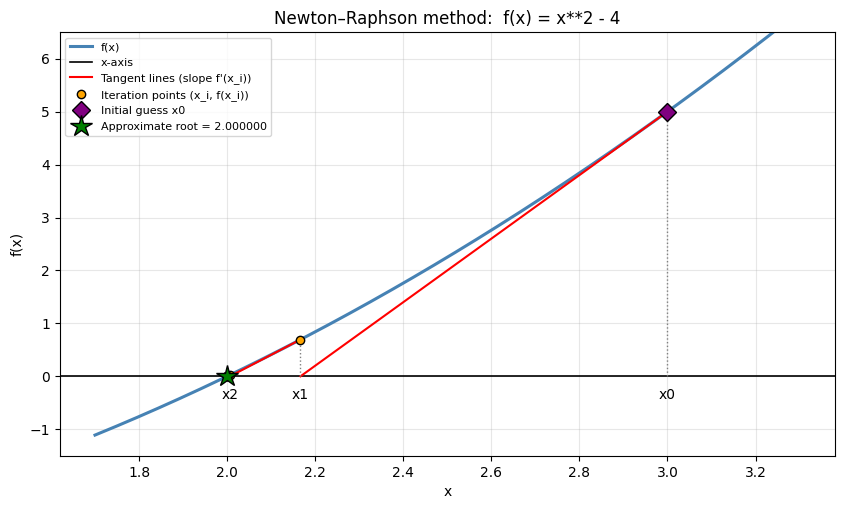

In [33]:
if result is not None:
    plot_result(result)

## 9. Testing and Validation

To check that the program is correct, it is tested on three equations with **known roots** (tolerance $10^{-10}$). A test passes only if the program reports convergence **and** the computed root agrees with the known root.

| Test | $f(x)$ | $x_0$ | Known root |
|---|---|---|---|
| 1 | $x^2-4$ | $3$ | $2$ |
| 2 | $x^3-x-2$ | $1.5$ | $\approx 1.52138$ |
| 3 | $\cos x - x$ | $0.5$ | $\approx 0.739085$ |

In [34]:
tests = [
    # (function, x0, known root)
    ("x**2 - 4",     "3",   2.0),
    ("x**3 - x - 2", "1.5", 1.5213797068045676),
    ("cos(x) - x",   "0.5", 0.7390851332151607),
]

summary = []
test_results = []
for number, (ftext, x0t, known) in enumerate(tests, start=1):
    res = solve(ftext, x0t, "1e-10", "50")
    test_results.append(res)
    print(f"Test {number}:  f(x) = {ftext},  x0 = {x0t},  known root = {known:.10f}")
    show_table(res, title=f"Test {number}")
    passed = res["converged"] and abs(res["root"] - known) < 1e-8
    print(f"-> computed root = {res['root']:.10f}   |error| = {abs(res['root'] - known):.2e}   "
          f"{'PASS ✔' if passed else 'FAIL ✘'}\n")
    summary.append([f"Test {number}", ftext, x0t, known, res["root"], len(res["rows"]), "PASS ✔" if passed else "FAIL ✘"])

summary_table = pd.DataFrame(summary, columns=["Test", "f(x)", "x0", "Known root", "Computed root", "Iterations", "Result"])
display(summary_table.style.format({"Known root": "{:.10f}", "Computed root": "{:.10f}"}).hide(axis="index")
        .set_caption("Summary of the tests")
        .set_table_styles([{"selector": "th", "props": [("background-color", "#1f3a5f"), ("color", "white")]}]))
print("All tests passed:", all(row[-1].startswith("PASS") for row in summary))

Test 1:  f(x) = x**2 - 4,  x0 = 3,  known root = 2.0000000000


Iteration i,x_i,f(x_i),f'(x_i),x_(i+1),Absolute error
0,3.00000000,5.0000e+00,6.000000,2.16666667,8.3333e-01
1,2.16666667,6.9444e-01,4.333333,2.00641026,1.6026e-01
2,2.00641026,2.5682e-02,4.012821,2.00001024,6.4000e-03
3,2.00001024,4.0960e-05,4.000020,2.00000000,1.0240e-05
4,2.00000000,1.0486e-10,4.000000,2.00000000,2.6214e-11


-> computed root = 2.0000000000   |error| = 0.00e+00   PASS ✔

Test 2:  f(x) = x**3 - x - 2,  x0 = 1.5,  known root = 1.5213797068


Iteration i,x_i,f(x_i),f'(x_i),x_(i+1),Absolute error
0,1.50000000,-1.2500e-01,5.750000,1.52173913,2.1739e-02
1,1.52173913,2.1369e-03,5.947070,1.52137981,3.5932e-04
2,1.52137981,5.8939e-07,5.943790,1.52137971,9.9160e-08
3,1.52137971,4.5297e-14,5.943789,1.52137971,7.5495e-15


-> computed root = 1.5213797068   |error| = 0.00e+00   PASS ✔

Test 3:  f(x) = cos(x) - x,  x0 = 0.5,  known root = 0.7390851332


Iteration i,x_i,f(x_i),f'(x_i),x_(i+1),Absolute error
0,0.50000000,3.7758e-01,-1.479426,0.75522242,2.5522e-01
1,0.75522242,-2.7103e-02,-1.685451,0.73914167,1.6081e-02
2,0.73914167,-9.4615e-05,-1.673654,0.73908513,5.6532e-05
3,0.73908513,-1.1810e-09,-1.673612,0.73908513,7.0565e-10
4,0.73908513,0.0000e+00,-1.673612,0.73908513,0.0000e+00


-> computed root = 0.7390851332   |error| = 0.00e+00   PASS ✔



Test,f(x),x0,Known root,Computed root,Iterations,Result
Test 1,x**2 - 4,3,2.0000000000,2.0000000000,5,PASS ✔
Test 2,x**3 - x - 2,1.5,1.5213797068,1.5213797068,4,PASS ✔
Test 3,cos(x) - x,0.5,0.7390851332,0.7390851332,5,PASS ✔


All tests passed: True


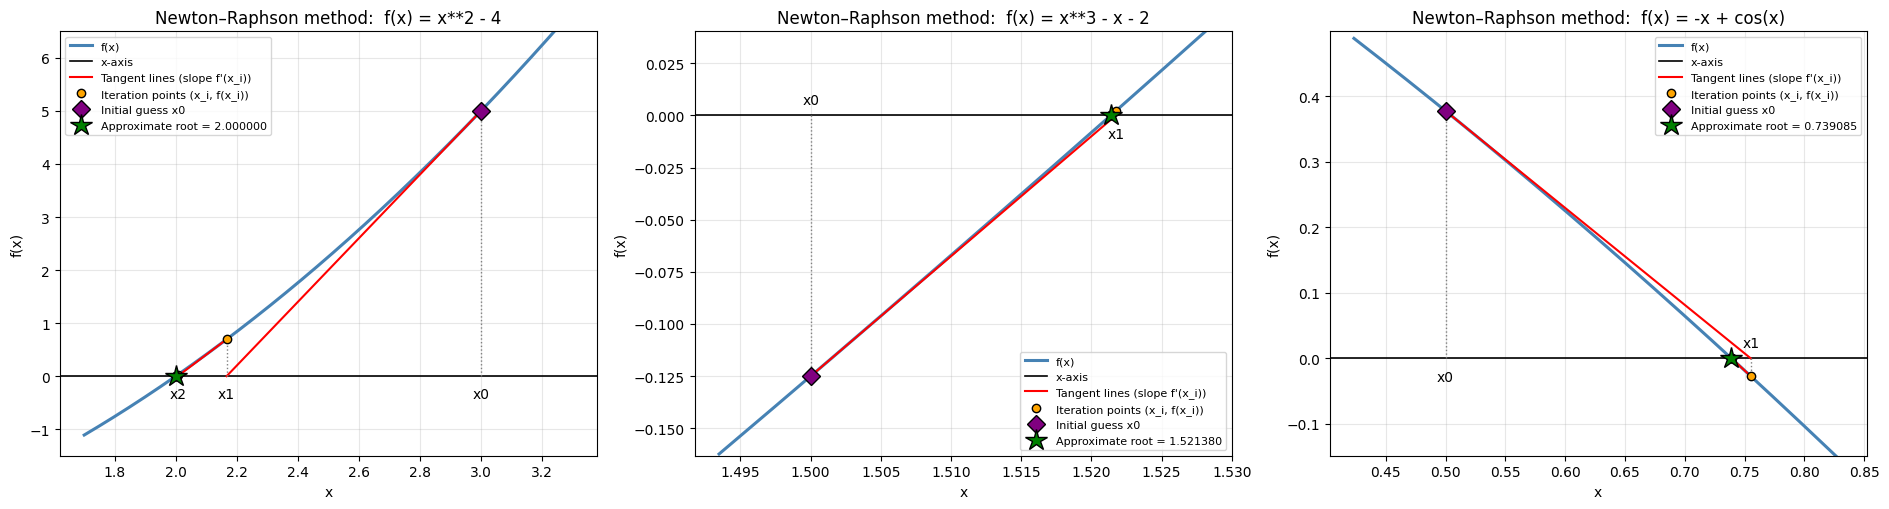

In [35]:
# Graphs of the three tests
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, res in zip(axes, test_results):
    plot_result(res, ax=ax)
plt.tight_layout()
plt.show()

### 9.1 Error-handling tests

The program must **never silently return a wrong answer**. Here every kind of problem is created on purpose, and the program must detect it and explain it.

In [36]:
bad_cases = [
    # (what we test,          f(x),        x0,    max iterations)
    ("Zero derivative",       "x**2 - 4",  "0",   "50"),
    ("Divergence",            "atan(x)",   "2",   "50"),
    ("Undefined value",       "log(x)",    "3",   "50"),
    ("Too few iterations",    "x**2",      "1",   "10"),
    ("Invalid expression",    "x^2 + * 3", "1",   "50"),
    ("Invalid initial guess", "x**2 - 4",  "abc", "50"),
    ("Negative tolerance",    "x**2 - 4",  "3",   "50"),
]

for name, ftext, x0t, max_it in bad_cases:
    tolerance = "-0.1" if name == "Negative tolerance" else "1e-10"
    print(f"--- {name}:  f(x) = {ftext},  x0 = {x0t}")
    res = solve(ftext, x0t, tolerance, max_it)
    if res is not None:
        print(f"    status: {res['status']}")
        print(f"    {res['message']}")
    print()

--- Zero derivative:  f(x) = x**2 - 4,  x0 = 0
    status: zero_derivative
    Iteration 0: f'(x) = 0.00e+00 is zero (or almost zero) at x = 0, so the tangent is horizontal and we would divide by zero. Try another initial guess.

--- Divergence:  f(x) = atan(x),  x0 = 2
    status: diverged
    Iteration 4: the iterates are growing without bound (|x| = 2.339e+10). The method diverges.

--- Undefined value:  f(x) = log(x),  x0 = 3
    status: undefined
    Iteration 1: the function is undefined or infinite at x = -0.295837. The method cannot continue.

--- Too few iterations:  f(x) = x**2,  x0 = 1
    status: max_iterations
    NOT converged: the tolerance 1e-10 was not reached in 10 iterations. The last approximation is NOT a verified root.

--- Invalid expression:  f(x) = x^2 + * 3,  x0 = 1
❌ Invalid input: 'x^2 + * 3' is not a valid expression. Example: x**3 - x - 2

--- Invalid initial guess:  f(x) = x**2 - 4,  x0 = abc
❌ Invalid input: The initial guess x0 must be a number, but you

**Remark:** for $f(x)=x^2$ the root $0$ is a *double* root ($f'(0)=0$ too). Newton–Raphson still approaches it, but only slowly (the error is only halved each step), so 10 iterations are not enough for $10^{-10}$ and the program correctly says **not converged**.

## 10. Try It Yourself (Playground)

Change the four values in the form below and run the cell. It shows the **table, the final results and the graph** in one go. Some ideas to try:

| $f(x)$ | $x_0$ | What to observe |
|---|---|---|
| `x**2 - 2` | `1` | converges to $\sqrt 2$ |
| `exp(x) - 3` | `1` | converges to $\ln 3$ |
| `x**3 - 2*x + 2` | `0` | the iterates **cycle** between 0 and 1 and never converge |
| `atan(x)` | `2` | **diverges** (a different `x0`, such as `0.5`, converges) |
| `x**2 - 4` | `0` | **zero derivative** at $x_0$ |

**Function:** $f(x)=e^{x} - 3$ &nbsp;&nbsp; **Derivative (SymPy):** $f'(x)=e^{x}$

Iteration i,x_i,f(x_i),f'(x_i),x_(i+1),Absolute error
0,5.00000000,1.4541e+02,148.413159,4.02021384,9.7979e-01
1,4.02021384,5.2713e+01,55.713018,3.07406122,9.4615e-01
2,3.07406122,1.8630e+01,21.629567,2.21276025,8.6130e-01
3,2.21276025,6.1409e+00,9.140913,1.54095505,6.7181e-01
4,1.54095505,1.6690e+00,4.669047,1.18348441,3.5747e-01
5,1.18348441,2.6573e-01,3.265734,1.10211416,8.1370e-02
6,1.10211416,1.0524e-02,3.010524,1.09861841,3.4957e-03
7,1.09861841,1.8373e-05,3.000018,1.09861229,6.1244e-06
8,1.09861229,5.6263e-11,3.000000,1.09861229,1.8754e-11



                        FINAL RESULTS                         
Approximate root                  : 1.098612288668
Final function value f(x)         : 4.4409e-16
Number of iterations              : 9
Final absolute error              : 1.8754e-11
Final relative error              : 1.7071e-11
Lecture condition at x0           : 0.9798   (should be < 1)
Lecture condition at final point  : 1.48e-16
Convergence status                : ✔ CONVERGED
The stopping condition |x_(i+1) - x_i| < 1e-10 was satisfied.


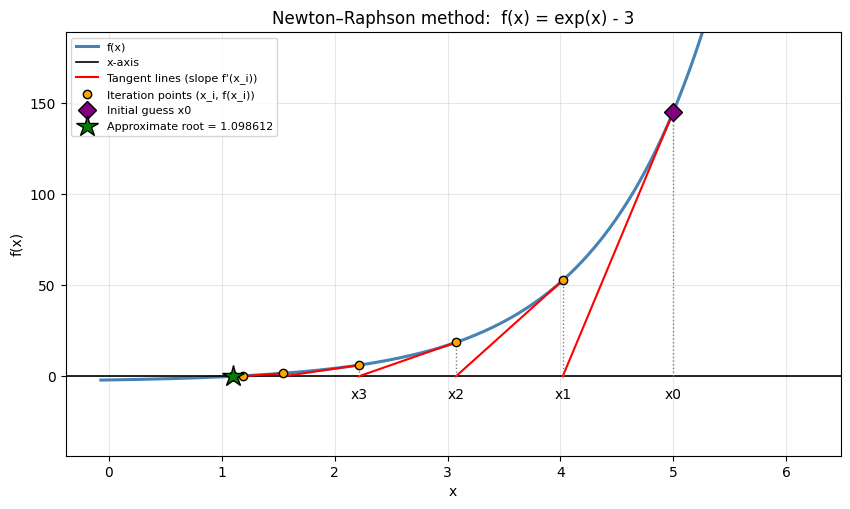

In [37]:
#@title Playground: try any function { display-mode: "form" }

my_function = "exp(x) - 3"   #@param {type:"string"}
my_x0       = "5"            #@param {type:"string"}
my_tol      = "1e-10"        #@param {type:"string"}
my_max_iter = "50"           #@param {type:"string"}

run_all(my_function, my_x0, my_tol, my_max_iter)

## 11. Final Conclusion

- The **Newton–Raphson method** was implemented with the exact formula from the lecture, $x_{i+1}=x_i-\dfrac{f(x_i)}{f'(x_i)}$, and the derivative is calculated automatically with SymPy. The path $x_0\to x_1\to x_2\to x_3\to\cdots$ is shown in a table and with tangent lines on a graph.
- The **stopping condition** is $|x_{i+1}-x_i|<\text{tolerance}$. The program says "converged" only when this condition is satisfied. Otherwise it reports the exact problem: zero derivative, undefined value, divergence, or too few iterations.
- In the **tests**, the program found the known roots of $x^2-4$, $x^3-x-2$ and $\cos x-x$ in only a few iterations. The error gets much smaller at every step (**quadratic convergence**).
- The error-handling tests show the **limits** of the method: it needs a good initial guess, it fails when $f'(x_i)=0$, it can diverge, and it converges slowly at a double root. This is why a result must always be checked.

*End of project.*

# **Thanks Dr/** **Abbas** **Mansour**
### For being an inspiration through this course